Task 3 - Sudoku

Author: Adam Gawęda

Code (Quick refactor from Rust code)

In [6]:
import random
import math
import copy


def whole_energy(sudoku: list[list[int]]) -> int:
    energy = 0
    for i in range(9):
        row = [0] * 10
        col = [0] * 10
        for j in range(9):
            row[sudoku[i][j]] += 1
            col[sudoku[j][i]] += 1

        for k in range(1, 10):
            if row[k] > 1:
                energy += row[k] - 1
            if col[k] > 1:
                energy += col[k] - 1
    return energy


def energy_count(sudoku: list[list[int]], p1: tuple[int, int], p2: tuple[int, int]) -> int:
    first_row, first_column = p1
    second_row, second_column = p2
    first_val = sudoku[first_row][first_column]
    second_val = sudoku[second_row][second_column]

    delta = 0

    for i in range(9):
        if sudoku[i][first_column] == first_val and i != first_row:
            delta += 1
        if sudoku[i][second_column] == second_val and i != second_row:
            delta += 1
        if sudoku[first_row][i] == first_val and i != first_column:
            delta += 1
        if sudoku[second_row][i] == second_val and i != second_column:
            delta += 1

    return delta


def fill_squares(sudoku: list[list[int]]):
    for box_idx in range(9):
        box_row = (box_idx // 3) * 3
        box_col = (box_idx % 3) * 3

        present = [False] * 10

        for row in range(box_row, box_row + 3):
            for col in range(box_col, box_col + 3):
                v = sudoku[row][col]
                if v != 0:
                    if present[v]:
                        raise ValueError(f"Invalid puzzle: digit {v} appears twice in box {box_idx}")
                    present[v] = True

        next_val = 1
        for row in range(box_row, box_row + 3):
            for col in range(box_col, box_col + 3):
                if sudoku[row][col] == 0:
                    while present[next_val]:
                        next_val += 1
                    sudoku[row][col] = next_val
                    present[next_val] = True
                    next_val += 1


def change_state(sudoku: list[list[int]], a: tuple[int, int], b: tuple[int, int]):
    sudoku[a[0]][a[1]], sudoku[b[0]][b[1]] = sudoku[b[0]][b[1]], sudoku[a[0]][a[1]]


def mutable_cells_in_box(fixed: list[list[bool]], box_index: int) -> list[tuple[int, int]]:
    box_row = (box_index // 3) * 3
    box_col = (box_index % 3) * 3
    cells = []
    for row in range(box_row, box_row + 3):
        for col in range(box_col, box_col + 3):
            if not fixed[row][col]:
                cells.append((row, col))
    return cells


def solve(sudoku: list[list[int]], fixed: list[list[bool]], show_progress: bool) -> bool:
    T_START = 0.5
    COOLING = 0.999_95
    ITER_PER_RUN = 100_000
    MAX_RESTARTS = 200
    RESYNC_EVERY = 50_000

    original = copy.deepcopy(sudoku)
    temp = T_START

    for restart in range(MAX_RESTARTS):
        # Przywracanie stanu początkowego (odpowiednik *sudoku = original w Rust)
        for i in range(9):
            for j in range(9):
                sudoku[i][j] = original[i][j]

        fill_squares(sudoku)
        energy = whole_energy(sudoku)
        total_iter = 0

        for _ in range(ITER_PER_RUN):
            total_iter += 1

            if energy == 0:
                if whole_energy(sudoku) == 0:
                    return True
                energy = whole_energy(sudoku)

            box_idx = random.randint(0, 8)
            candidates = mutable_cells_in_box(fixed, box_idx)

            if len(candidates) < 2:
                continue

            i1 = random.randint(0, len(candidates) - 1)
            i2 = random.randint(0, len(candidates) - 1)
            while i2 == i1:
                i2 = random.randint(0, len(candidates) - 1)

            p1 = candidates[i1]
            p2 = candidates[i2]

            delta = -1 * energy_count(sudoku, p1, p2)
            change_state(sudoku, p1, p2)
            delta += energy_count(sudoku, p1, p2)

            if delta <= 0:
                energy += delta
            else:
                try:
                    probability = math.exp(-delta / temp)
                except OverflowError:
                    probability = 0.0

                if random.random() < probability:
                    energy += delta
                else:
                    change_state(sudoku, p1, p2)

            temp *= COOLING

            if total_iter % RESYNC_EVERY == 0:
                energy = whole_energy(sudoku)

    return False

Visualisation

In [7]:
import matplotlib.pyplot as plt
import copy

def draw_sudoku(sudoku, fixed, title="Sudoku"):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_title(title, fontsize=16, pad=15)
    ax.set_xlim(0, 9)
    ax.set_ylim(0, 9)
    ax.invert_yaxis()  # Odwracamy oś Y, aby wiersz 0 był na górze
    ax.axis('off')     # Ukrywamy osie układu współrzędnych

    # Rysowanie linii siatki
    for i in range(10):
        # Grubsza linia dla krawędzi bloków 3x3
        linewidth = 2.5 if i % 3 == 0 else 0.8
        ax.axhline(i, color='red', linewidth=linewidth)
        ax.axvline(i, color='red', linewidth=linewidth)

    # Wstawianie cyfr
    for row in range(9):
        for col in range(9):
            val = sudoku[row][col]
            if val != 0:
                # Czarne cyfry to zablokowane (oryginalne), niebieskie to wyliczone
                color = 'red' if fixed[row][col] else 'blue'
                font_weight = 'bold' if fixed[row][col] else 'normal'
                ax.text(col + 0.5, row + 0.5, str(val),
                        ha='center', va='center', fontsize=16,
                        color=color, weight=font_weight)

    plt.tight_layout()
    plt.show()

Let's see how it went

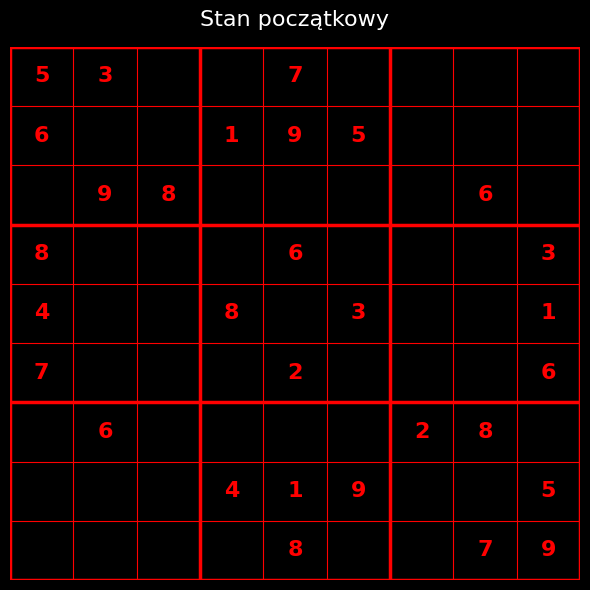

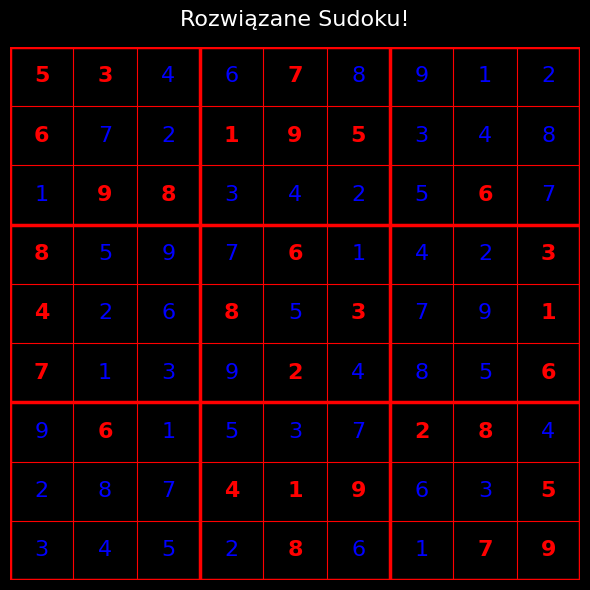

In [8]:
# Przykładowe Sudoku (0 oznacza puste pole)
puzzle = [
    [5,3,0, 0,7,0, 0,0,0],
    [6,0,0, 1,9,5, 0,0,0],
    [0,9,8, 0,0,0, 0,6,0],
    [8,0,0, 0,6,0, 0,0,3],
    [4,0,0, 8,0,3, 0,0,1],
    [7,0,0, 0,2,0, 0,0,6],
    [0,6,0, 0,0,0, 2,8,0],
    [0,0,0, 4,1,9, 0,0,5],
    [0,0,0, 0,8,0, 0,7,9]
]

# Tworzenie macierzy wartości stałych
fixed = [[val != 0 for val in row] for row in puzzle]

# 1. Rysujemy stan początkowy
draw_sudoku(puzzle, fixed, "Stan początkowy")

# 2. Rozwiązujemy (używamy kopii, jeśli nie chcemy modyfikować oryginału w locie)
is_solved = solve(puzzle, fixed, show_progress=False)

# 3. Rysujemy wynik
if is_solved:
    draw_sudoku(puzzle, fixed, "Rozwiązane Sudoku!")
else:
    draw_sudoku(puzzle, fixed, "Nie udało się znaleźć rozwiązania...")

I did made it originally in Rust, you can check it out on: https://github.com/adamgaweda/Rust_Sudoku_Solver